<a href="https://colab.research.google.com/github/munyeshyakajmv1/colab-git-assignment2-JMV/blob/main/Assignment_6_California_Housing_Completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Assignment 6: House Price Prediction Using California Housing Data**

**Course:** Data Analytics and Artificial Intelligence  
**Project:** Simple Machine Learning Project Cycle  
**Student name:** Jean Marie Vianney Munyeshyaka

**Date:** 23 December 2026

**Link to Github and Colab**

Colab
https://colab.research.google.com/drive/122L6t42vfNEsppSDjHPRZuoJRn23F7M1?usp=sharing

GitHub

https://github.com/munyeshyakajmv1/colab-git-assignment2-JMV/blob/main/Assignment_6_California_Housing_Completed.ipynb


**Objective:** Build and evaluate a regression model that predicts median house values using the California Housing dataset from scikit-learn.

## **1. Introduction**

This notebook follows the main stages of a supervised machine learning project: importing libraries, collecting data, inspecting and exploring the dataset, preprocessing, training a regression model, evaluating its performance, and making a prediction for a new observation.

The target variable is **MedHouseVal**, which represents the median house value for a California block group. In the original dataset, target values are expressed in units of **$100,000**. For example, a target value of `2.5` represents approximately `$250,000`.

## **2. Dataset feature descriptions**

| Feature | Description |
|---|---|
| `MedInc` | Median income in the block group |
| `HouseAge` | Median house age in the block group |
| `AveRooms` | Average number of rooms per household |
| `AveBedrms` | Average number of bedrooms per household |
| `Population` | Block group population |
| `AveOccup` | Average number of household members |
| `Latitude` | Block group latitude |
| `Longitude` | Block group longitude |
| `MedHouseVal` | Median house value in the block group (target) |

The eight input features are numerical measurements. They are treated as continuous/numeric variables for this regression exercise. The dataset does not contain a categorical input feature in its supplied form.


## **3. Import the required libraries**

The libraries below support data manipulation, numerical calculations, visualization, dataset loading, splitting the data, training a linear regression model, and evaluating predictions.

In [2]:
# Import pandas for working with tabular data.
import pandas as pd

# Import NumPy for numerical calculations.
import numpy as np

# Import Matplotlib and Seaborn for data visualization.
import matplotlib.pyplot as plt
import seaborn as sns

# Import the California Housing dataset.
from sklearn.datasets import fetch_california_housing

# Import the function used to split data into training and testing sets.
from sklearn.model_selection import train_test_split

# Import Linear Regression, the regression algorithm used in this assignment.
from sklearn.linear_model import LinearRegression

# Import evaluation metrics for measuring regression model performance.
from sklearn.metrics import mean_squared_error, r2_score

# Apply a consistent visual style to plots.
sns.set_theme(style="whitegrid")

# Display plots directly below the code cell in a Jupyter/Colab notebook.
%matplotlib inline

## **4. Data collection and loading**

Load the California Housing dataset from `sklearn.datasets`. Convert its feature data into a pandas DataFrame and add the target variable as a column named `MedHouseVal`.

The `as_frame=True` option asks scikit-learn to provide pandas objects, while the explicit DataFrame construction below makes the feature and target structure clear.

In [3]:
# Download/load the California Housing dataset from scikit-learn.
# The first run may require an internet connection to download the dataset.
housing = fetch_california_housing(as_frame=True)

# Copy the eight input features into a DataFrame.
df = housing.data.copy()

# Add the target variable using the required column name.
df["MedHouseVal"] = housing.target

# Store the names of the input features and the target for later use.
feature_names = list(housing.feature_names)
target_name = "MedHouseVal"

# Display the dimensions and a confirmation message.
print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of input features: {len(feature_names)}")
print(f"Target variable: {target_name}")

Dataset loaded successfully.
Number of rows: 20,640
Number of input features: 8
Target variable: MedHouseVal


## **5. Quick check of the data**

First, inspect the first five records. Then review the column data types, non-null counts, and descriptive statistics.

The input variables are numerical. There are no categorical variables in the original feature set supplied by scikit-learn. `MedHouseVal` is the continuous numerical target that the regression model will predict.

In [4]:
# Display the first five rows to inspect the dataset.
display(df.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
# Display the dataset structure, including data types and non-null counts.
print("Dataset information:")
df.info()

# Display descriptive statistics for all numerical columns.
print("\nDescriptive statistics:")
display(df.describe().T)

# Separate the input feature names from the target name.
print("\nInput features:")
print(feature_names)

print("\nTarget variable:")
print(target_name)

# Show the data type of each column to identify numerical/categorical fields.
print("\nColumn data types:")
print(df.dtypes)

# Identify categorical columns, if any.
categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()
if categorical_columns:
    print("\nCategorical columns:", categorical_columns)
else:
    print("\nNo categorical columns are present in the supplied dataset.")

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010



Input features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target variable:
MedHouseVal

Column data types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

No categorical columns are present in the supplied dataset.


## **6. Exploratory data analysis and preprocessing**

### 6.1 Check for missing values

Check the number of null values in every column. If missing values are found, the preprocessing approach should be selected based on the column and the extent of missingness.

For this dataset, the code also checks for duplicate rows. The original California Housing dataset is generally supplied as a complete numerical dataset, but the checks are included so the notebook verifies the data rather than assuming it is clean.

In [6]:
# Count missing values in each column.
missing_values = df.isnull().sum()

print("Missing values by column:")
display(missing_values.to_frame(name="Missing Count"))

# Calculate the overall number of missing cells.
total_missing = int(missing_values.sum())
print(f"Total missing values in the dataset: {total_missing}")

# Check for duplicate records.
duplicate_count = int(df.duplicated().sum())
print(f"Number of duplicate rows: {duplicate_count}")

# Handle missing values only if they are present.
# Median imputation is used for numerical columns because it is less affected
# by extreme values than the mean.
if total_missing > 0:
    for column in df.columns:
        if df[column].isnull().any():
            df[column] = df[column].fillna(df[column].median())
    print("Missing numerical values were filled using each column's median.")
else:
    print("No missing values were found; no imputation was necessary.")

# Remove duplicate rows only if duplicates are present.
if duplicate_count > 0:
    df = df.drop_duplicates().copy()
    print("Duplicate rows were removed.")
else:
    print("No duplicate rows were found.")

Missing values by column:


,Missing Count
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


Total missing values in the dataset: 0
Number of duplicate rows: 0
No missing values were found; no imputation was necessary.
No duplicate rows were found.


### 6.2 Visualize relationships between features and the target

Scatter plots help us inspect how each input feature relates to `MedHouseVal`. Each point represents a block group. A visible pattern may indicate a relationship, while a widely scattered cloud may indicate a weaker or more complex relationship.

The function below accepts a list of feature names and automatically creates a scatter plot for each feature against the target.

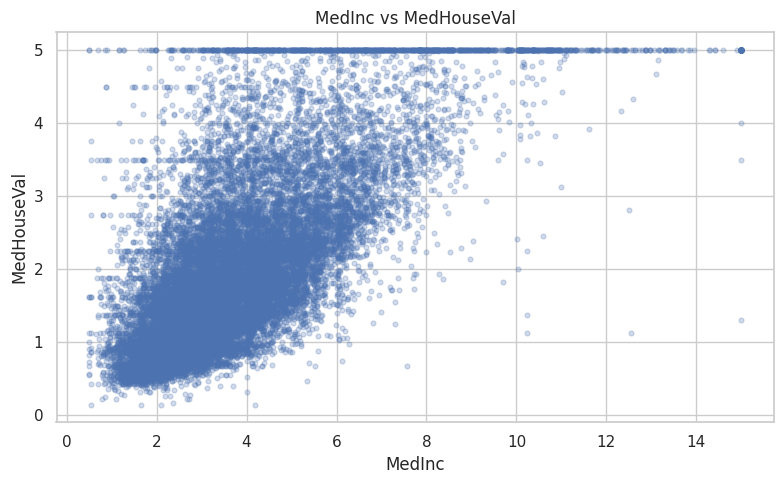

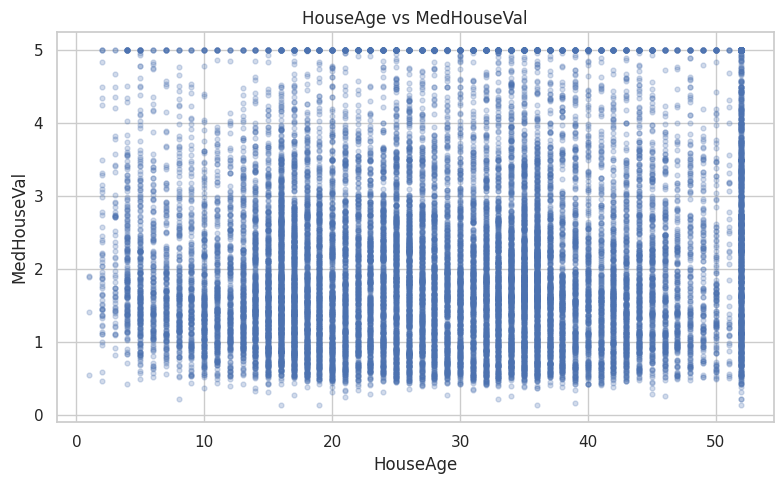

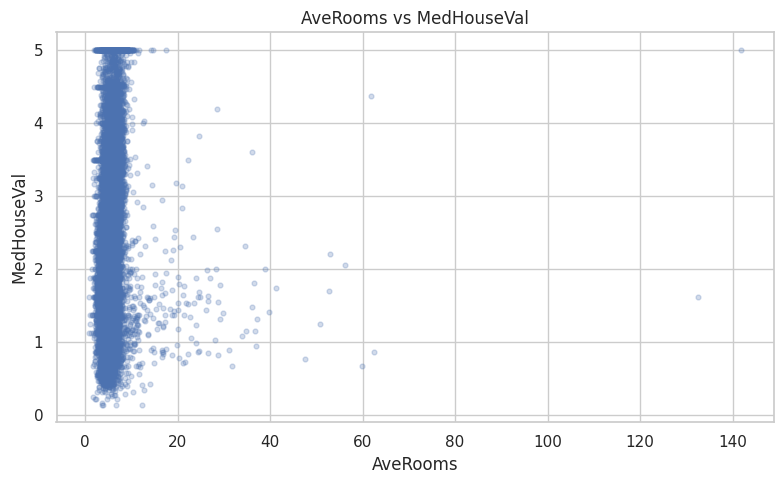

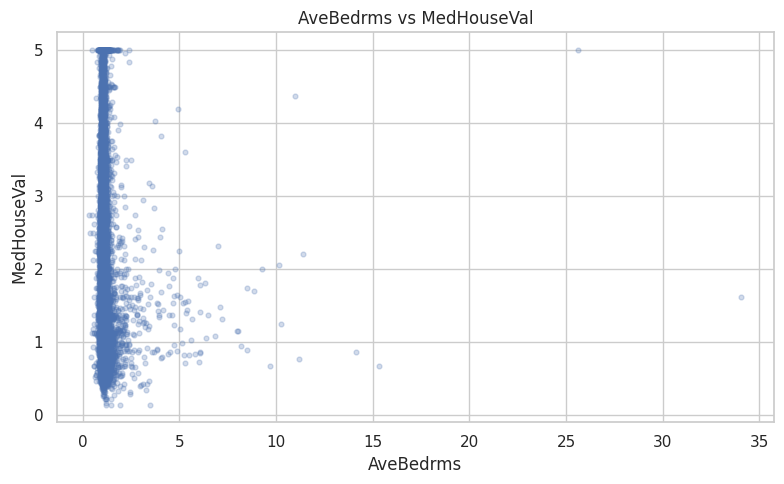

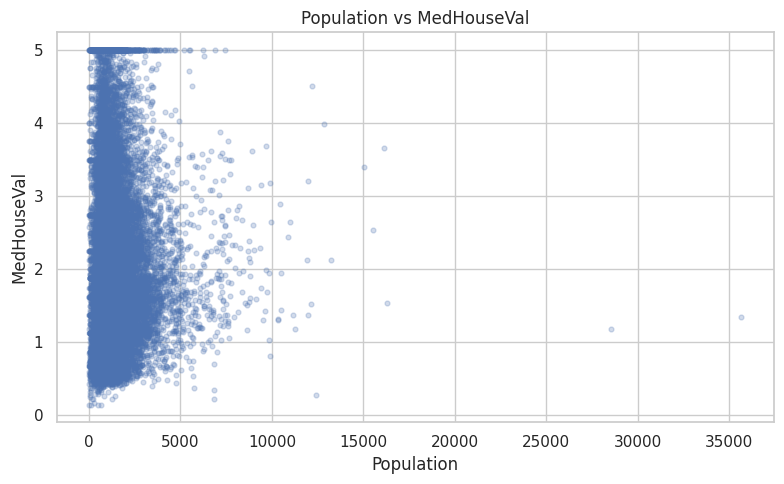

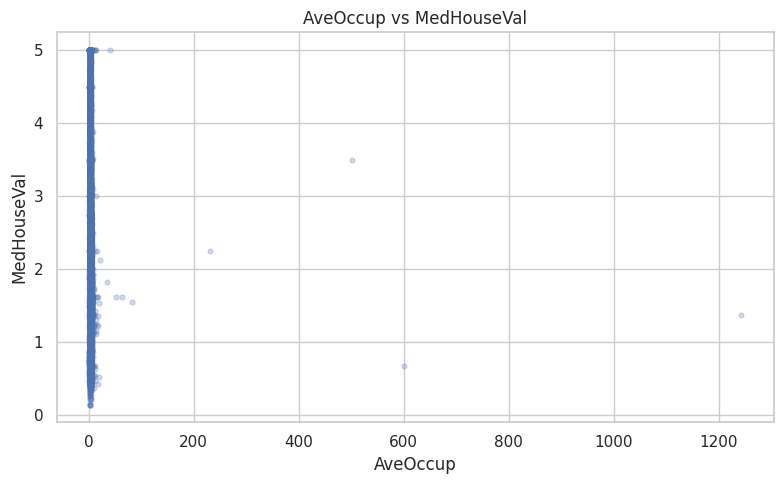

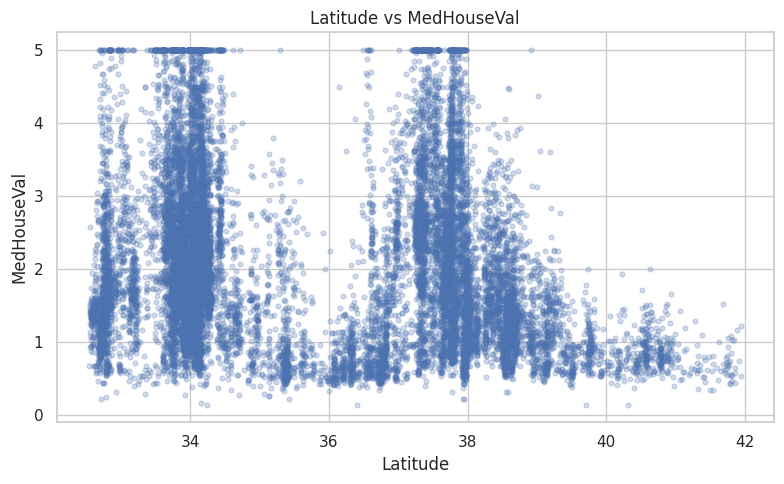

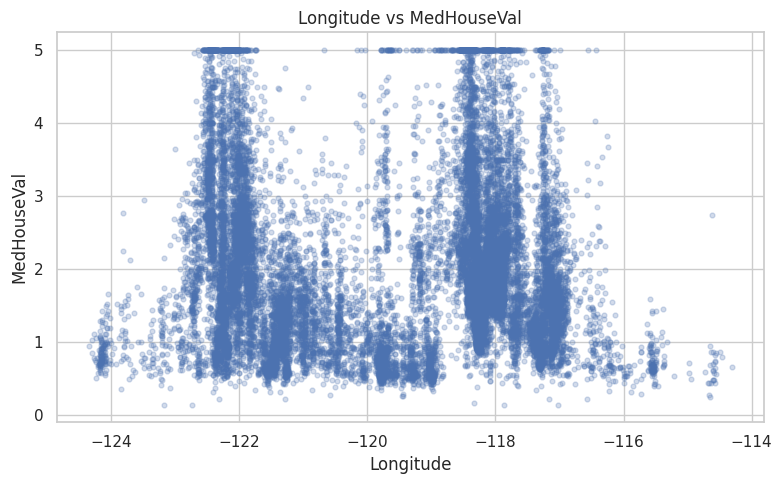

In [7]:
# Define a reusable function to create scatter plots for selected features.
def plot_features_vs_target(data, features, target):
    """Plot each selected feature against a numerical target variable."""

    # Confirm that the requested target and features exist in the DataFrame.
    missing_columns = [col for col in features + [target] if col not in data.columns]
    if missing_columns:
        raise ValueError(f"The following columns are not in the DataFrame: {missing_columns}")

    # Create one scatter plot for each feature.
    for feature in features:
        plt.figure(figsize=(8, 5))
        plt.scatter(
            data[feature],
            data[target],
            alpha=0.25,
            s=12
        )
        plt.title(f"{feature} vs {target}")
        plt.xlabel(feature)
        plt.ylabel(target)
        plt.tight_layout()
        plt.show()

# Visualize all eight input features against the target variable.
plot_features_vs_target(df, feature_names, target_name)

### 6.3 Focus on the features highlighted in the assignment

The assignment specifically highlights `MedInc`, `AveRooms`, `AveOccup`, and `HouseAge`. The same function is called again for these four features so their relationships can be reviewed together as the main examples for the EDA discussion.

**Initial observations to look for:**
- `MedInc`: check whether higher median income is generally associated with higher median house value.
- `AveRooms`: look for a possible relationship, while noting that unusually large values may affect the scale.
- `AveOccup`: check whether household occupancy shows a clear or weak pattern.
- `HouseAge`: inspect whether house age alone appears to explain much of the variation in house values.

These are visual observations, not proof of causation.

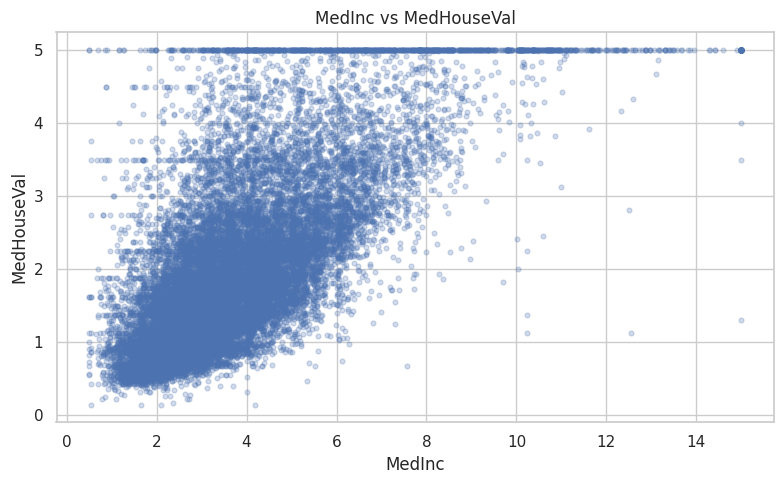

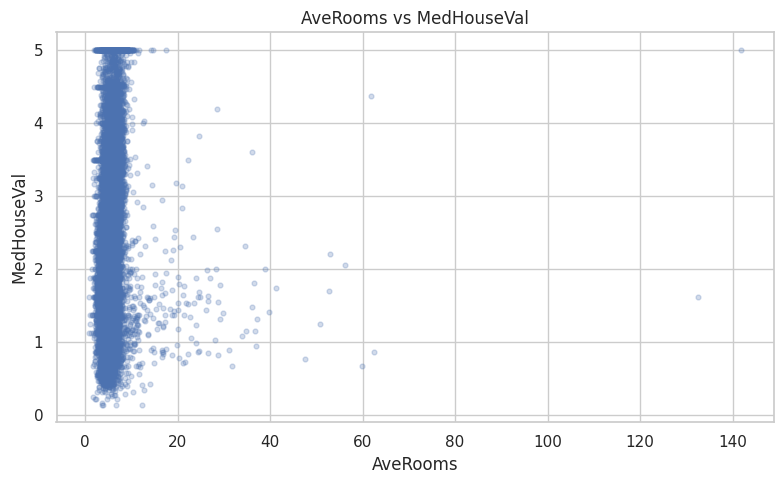

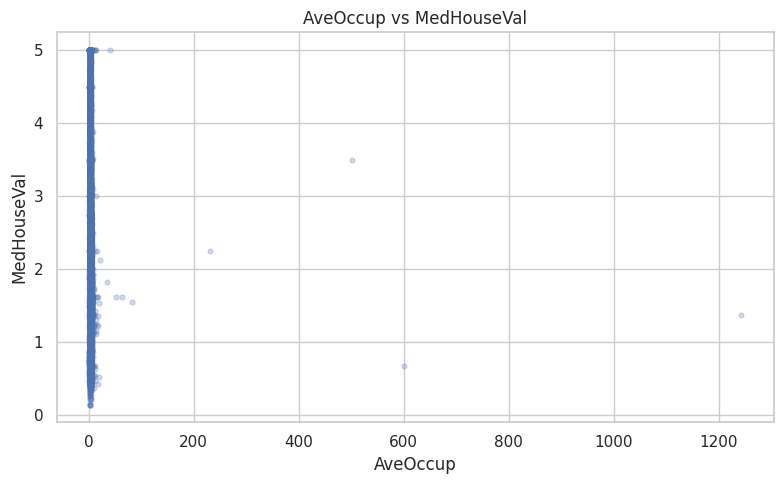

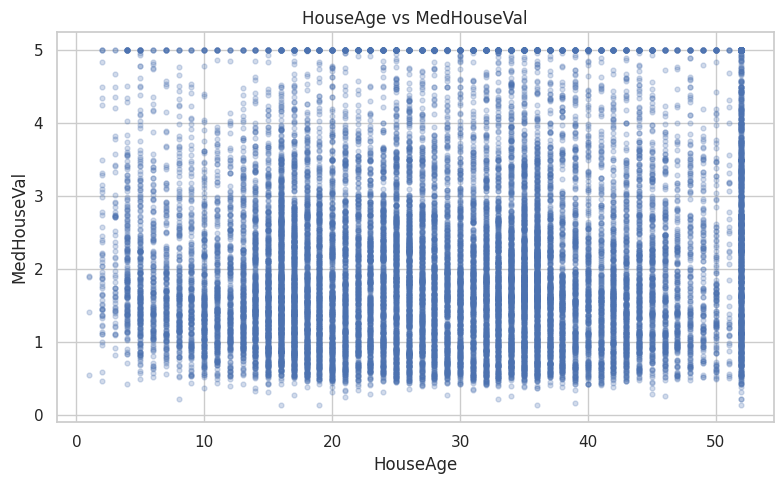

In [8]:
# Plot the four features specifically listed in the assignment.
selected_features = ["MedInc", "AveRooms", "AveOccup", "HouseAge"]
plot_features_vs_target(df, selected_features, target_name)

## **7. Machine learning model training**

### 7.1 Define the input features and target

`X` contains the eight independent input features. `y` contains the target variable, `MedHouseVal`.

### 7.2 Split the data

Use an 80/20 train-test split:
- 80% of the observations are used to train the model.
- 20% are held back to test how well the model predicts observations it did not train on.

A fixed `random_state` makes the split reproducible.

In [9]:
# Define X as the eight input features and y as the target variable.
X = df[feature_names].copy()
y = df[target_name].copy()

# Split the dataset into 80% training data and 20% testing data.
# random_state=42 ensures that the same split is produced when rerunning the notebook.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display the number of records in each subset.
print("Training and testing data sizes:")
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

Training and testing data sizes:
X_train: (16512, 8)
X_test:  (4128, 8)
y_train: (16512,)
y_test:  (4128,)


### 7.3 Select and train the regression model

Use **Linear Regression**, as suggested in the assignment. Linear regression estimates a relationship between the input features and a continuous target by fitting coefficients that minimize the sum of squared prediction errors on the training data.

The model is trained only on the training subset. The test subset is kept separate for an unbiased evaluation.

In [10]:
# Create the Linear Regression model.
linear_model = LinearRegression()

# Train the model using only the training data.
linear_model.fit(X_train, y_train)

print("Linear Regression model training completed.")

# Display the learned intercept and feature coefficients.
print(f"Model intercept: {linear_model.intercept_:.4f}")

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": linear_model.coef_
}).sort_values(by="Coefficient", key=abs, ascending=False)

print("\nModel coefficients (sorted by absolute size):")
display(coefficients)

Linear Regression model training completed.
Model intercept: -37.0233

Model coefficients (sorted by absolute size):


,Feature,Coefficient
3,AveBedrms,0.783145
0,MedInc,0.448675
7,Longitude,-0.433708
6,Latitude,-0.419792
2,AveRooms,-0.123323
1,HouseAge,0.009724
5,AveOccup,-0.003526
4,Population,-0.000002


## **8. Model evaluation**

Generate predictions for the test set and calculate two regression metrics:

- **Root Mean Squared Error (RMSE):** measures the typical size of prediction errors, with larger errors receiving more weight. A lower RMSE is better.
- **R-squared (R²):** measures the proportion of variation in the target explained by the model on the test data. A value closer to 1 indicates a better fit. It can be negative if the model performs worse than predicting the test-set mean.

The target is measured in units of $100,000, so RMSE is in the same units. The code also converts RMSE to an approximate dollar amount for easier interpretation.

In [11]:
# Predict median house values for observations in the test set.
y_pred = linear_model.predict(X_test)

# Calculate Root Mean Squared Error.
# squared=False requests RMSE directly in supported recent scikit-learn versions.
# The square-root calculation below is used for compatibility with older versions.
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# Calculate the R-squared score.
r2 = r2_score(y_test, y_pred)

# Display the evaluation metrics.
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R²): {r2:.4f}")

# Convert RMSE from units of $100,000 to approximate dollars.
rmse_dollars = rmse * 100000
print(f"Approximate RMSE in dollars: ${rmse_dollars:,.2f}")

Mean Squared Error (MSE): 0.5559
Root Mean Squared Error (RMSE): 0.7456
R-squared (R²): 0.5758
Approximate RMSE in dollars: $74,558.14


### 8.1 Compare actual and predicted values

A small sample of actual and predicted test values helps us see how close the model's predictions are to the observed target values. The scatter plot compares all actual test values with their predictions. Points closer to the diagonal reference line represent more accurate predictions.

,Actual MedHouseVal,Predicted MedHouseVal
20046,0.47700,0.719123
3024,0.45800,1.764017
15663,5.00001,2.709659
20484,2.18600,2.838926
9814,2.78000,2.604657
13311,1.58700,2.011754
7113,1.98200,2.645500
7668,1.57500,2.168755
18246,3.40000,2.740746
5723,4.46600,3.915615


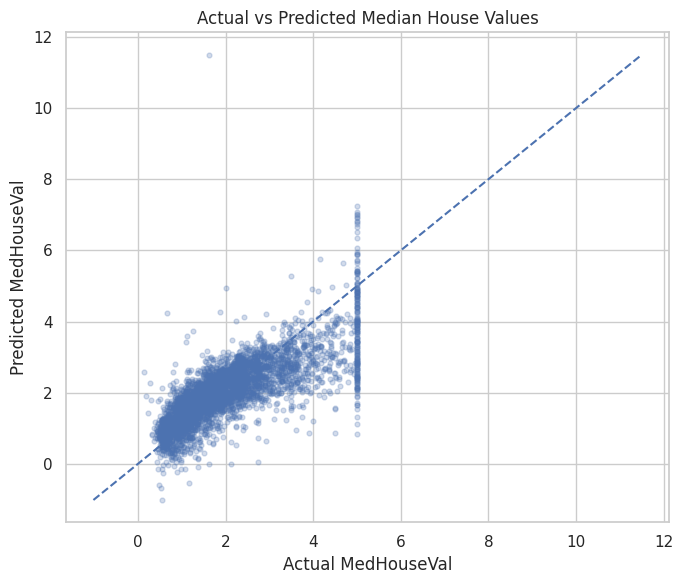

In [12]:
# Create a table comparing actual and predicted values for the first ten test records.
comparison = pd.DataFrame({
    "Actual MedHouseVal": y_test,
    "Predicted MedHouseVal": y_pred
})

display(comparison.head(10))

# Plot actual values against predicted values.
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.25, s=12)

# Add a diagonal reference line representing perfect predictions.
lower_bound = min(y_test.min(), y_pred.min())
upper_bound = max(y_test.max(), y_pred.max())
plt.plot(
    [lower_bound, upper_bound],
    [lower_bound, upper_bound],
    linestyle="--"
)

plt.title("Actual vs Predicted Median House Values")
plt.xlabel("Actual MedHouseVal")
plt.ylabel("Predicted MedHouseVal")
plt.tight_layout()
plt.show()

## **9. Model prediction for a new observation**



In [13]:
# Create one new observation using the example values in the assignment.
# The dictionary keys match the model's eight training feature names.
new_house = pd.DataFrame([{
    "MedInc": 3,
    "HouseAge": 30,
    "AveRooms": 6,
    "AveBedrms": 1,
    "Population": 1500,
    "AveOccup": 3,
    "Latitude": 34,
    "Longitude": -118
}])

# Reorder the new observation columns to match the training feature order.
new_house = new_house[feature_names]

# Predict the median house value for the new observation.
predicted_value = linear_model.predict(new_house)[0]

# Convert the prediction to an approximate dollar value.
predicted_value_dollars = predicted_value * 100000

print("New house input:")
display(new_house)

print(f"Predicted MedHouseVal: {predicted_value:.4f}")
print(f"Approximate predicted median house value: ${predicted_value_dollars:,.2f}")

New house input:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,3,30,6,1,1500,3,34,-118


Predicted MedHouseVal: 1.5487
Approximate predicted median house value: $154,866.33


## **10. Conclusion**

In this assignment, I successfully developed a Linear Regression model to predict median house values using the California Housing dataset. I performed data exploration, checked for missing values, created visualizations, trained the model using an 80/20 train-test split, and evaluated its performance.

The model achieved an MSE of 0.5559, an RMSE of 0.7456 (approximately $74,558), and an R-squared value of 0.5758. This means the model explains approximately 57.58% of the variation in median house values.

Using the example housing data, the model predicted a median house value of approximately $154,866.33.

Overall, this assignment helped me understand the basic machine learning workflow and how regression models can be used for house price prediction. Although the model provides useful predictions, its performance could be improved by testing more advanced algorithms such as Random Forest Regression and Gradient Boosting.